# Initial value problems and one-step methods

**Source:** CompSci §§4.1–4.3, pp. 22–27 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For $y'=f(t,y)$, continuity in time and local Lipschitz continuity in state give local existence and uniqueness. A bound on perturbations over a fixed interval is distinct from asymptotic decay. Integrating over one step gives $y_{n+1}=y_n+\int_{t_n}^{t_n+h}f(s,y(s))\,ds$. Forward Euler uses the left endpoint; Heun uses a forward predictor and averages slopes; RK4 uses slopes at the start, two midpoints and the end with weights $1,2,2,1$. Backward Euler evaluates the slope at the new state, trapezoidal/Crank–Nicolson averages the true endpoint slopes, and implicit midpoint evaluates at the midpoint state and time. The latter two coincide for the autonomous linear example below.

Implicit methods generally require a nonlinear solve. Fixed-point iteration for backward Euler contracts if $hL_f<1$; stability of the time integrator does not guarantee convergence of that iteration. Dividing a one-step defect by $h$ gives the local residual. Consistency controls that residual; stability bounds accumulation; under these hypotheses the maximum global error over a fixed interval converges with the method's order.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


Forward Euler observed order 1.01
Backward Euler observed order 0.991
Heun observed order 2.017
Trapezoid / midpoint observed order 2.0
RK4 observed order 4.019


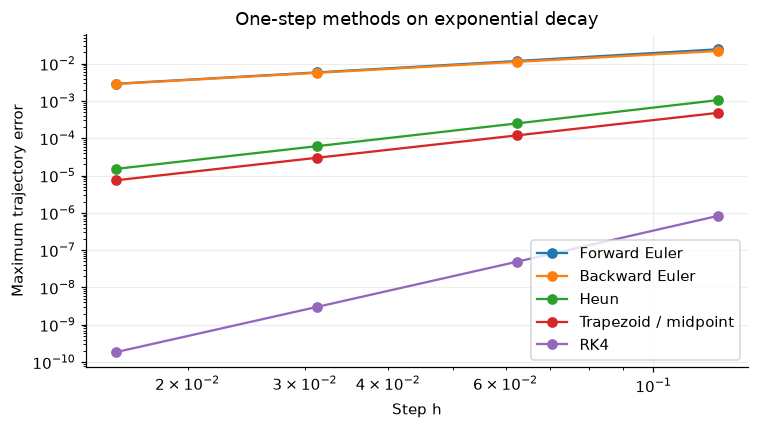

In [2]:
def step(f,t,y,h,method):
    k1=f(t,y)
    if method=="Forward Euler": return y+h*k1
    if method=="Heun": return y+h*(k1+f(t+h,y+h*k1))/2
    k2=f(t+h/2,y+h*k1/2); k3=f(t+h/2,y+h*k2/2)
    k4=f(t+h,y+h*k3)
    return y+h*(k1+2*k2+2*k3+k4)/6

def run(n,method):
    h=1/n; y=1.; err=0.
    for i in range(n):
        if method=="Backward Euler": y/=1+h
        elif method=="Trapezoid / midpoint": y*=(1-h/2)/(1+h/2)
        else: y=step(lambda t,y:-y,i*h,y,h,method)
        err=max(err,abs(y-np.exp(-(i+1)*h)))
    return err

ns=np.array([8,16,32,64])
fig,ax=plt.subplots(figsize=(7,4))
for method,p in [("Forward Euler",1),("Backward Euler",1),("Heun",2),
                 ("Trapezoid / midpoint",2),("RK4",4)]:
    errors=np.array([run(n,method) for n in ns])
    rate=np.log2(errors[-2]/errors[-1])
    assert abs(rate-p)<.07
    print(method, "observed order", round(rate,3))
    ax.loglog(1/ns,errors,"o-",label=method)
ax.set(xlabel="Step h",ylabel="Maximum trajectory error",title="One-step methods on exponential decay")
ax.legend(); show(fig,"04-convergence")
# Nonlinear implicit step: y'=-y², h=.2, y0=1.
h=.2; z=1-h
for _ in range(60): z=1-h*z*z
assert abs(z+h*z*z-1)<1e-13

## Worked exercise

**What is the forward Euler local residual order?** Taylor's formula gives a one-step defect $h^2 y''(\xi)/2$; dividing by $h$ yields $O(h)$. The measured slopes apply to this smooth fixed-time problem, not arbitrary equations or long integrations.

## Further practice

Derive the Euler local defect using a Taylor expansion. Add a perturbed initial value and distinguish problem sensitivity from discretisation error.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.